<a href="https://colab.research.google.com/github/Endoefa/ovo/blob/main/Tutorial_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### A vanilla CNN for object detection (binary classification + localisation)
The output values are (objectness & 4 bounding box values)

In [ ]:
import keras
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import datasets

In [ ]:
import numpy as np
import random

# !!!设置随机种子以保证结果可复现!!!
tf.random.set_seed(0)
np.random.seed(0)
random.seed(0)

# 使用 20 张图片训练模型
no_of_images = 20

# 创建一些假的标签值作为示例，假设只有 1 个类别
# 0 表示背景，1 表示物体
train_class = np.random.randint(0, 2, no_of_images)

# 加载 CIFAR-10 数据集
(train_images, _), (_, _) = datasets.cifar10.load_data()

# 只使用前 20 张图片
train_images = train_images[0:no_of_images, :, :, :]

# 创建一些假的边界框数据（图片数量、x、y、宽度、高度）
train_loc = tf.random.uniform([tf.shape(train_images)[0], 4])

# 把类别标签和边界框标签合并为训练标签
train_labels = (train_class, train_loc)

# 假设我们有一些测试图片，但实际上只是复制了训练图片和标签
test_images = train_images.copy()
test_labels = train_labels

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
print(train_labels)  # 下面会看到这些标签的样子
# 可以看到，边界框的数值被缩放到了 0 到 1 之间
# 它们是相对于图片的高度和宽度表示的百分比

(array([0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1]), <tf.Tensor: shape=(20, 4), dtype=float32, numpy=
array([[0.29197514, 0.20656645, 0.53539073, 0.5612575 ],
       [0.4166745 , 0.80782795, 0.4932251 , 0.99812925],
       [0.69673514, 0.1253736 , 0.7098167 , 0.6624156 ],
       [0.57225657, 0.36475348, 0.42051828, 0.630057  ],
       [0.913813  , 0.6616472 , 0.83347356, 0.08395803],
       [0.2797594 , 0.0155232 , 0.72637355, 0.7655387 ],
       [0.6798667 , 0.53272796, 0.7565141 , 0.04742193],
       [0.05037141, 0.75174344, 0.1727128 , 0.3119352 ],
       [0.29137385, 0.10051239, 0.16567075, 0.7696651 ],
       [0.58567977, 0.98200965, 0.9148327 , 0.14166534],
       [0.09756553, 0.6062784 , 0.17792177, 0.518052  ],
       [0.9821211 , 0.17577946, 0.04563165, 0.59754145],
       [0.5629543 , 0.80507433, 0.5839267 , 0.10312653],
       [0.94490445, 0.28259814, 0.55285144, 0.27949476],
       [0.07950485, 0.38949406, 0.0698117 , 0.04193437],
       [0.9238986 , 0.8752

In [ ]:
opt = tf.keras.optimizers.Adam(learning_rate=0.0001)  # 选择一个优化器——这里不需要理解其内部原理

# Adam 优化器

# 使用一个已有的 CNN 架构——这里使用带预训练权重的 VGG16
# 将 "include_top" 设置为 False，移除原有的全连接分类层；之后我们会自己添加一些全连接层
base_model = tf.keras.applications.VGG16(weights="imagenet", include_top=False)

print(base_model.output_shape)

# 在卷积网络部分的输出后添加全局平均池化层
avg = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)

# 在输出层中添加 1 个神经元，用于输出类别标签
# 使用 sigmoid 激活函数，让输出成为 0 到 1 之间的数值
class_output = tf.keras.layers.Dense(1, activation="sigmoid")(avg)

# 在输出层中额外添加 4 个神经元，分别表示边界框的位置和大小
# 即 x、y、width 和 height
loc_output = tf.keras.layers.Dense(4)(avg)

# 把这 5 个神经元的结果组合成模型输出
model = tf.keras.Model(inputs=base_model.input, outputs=[class_output, loc_output])

# 类别预测使用二元交叉熵损失，边界框回归使用均方误差损失
model.compile(
    loss=["binary_crossentropy", "mse"],
    loss_weights=[0.8, 0.2],
    optimizer=opt,
    metrics=["accuracy", "mse"]
)

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(None, None, None, 512)


In [ ]:
history = model.fit(
    train_images,
    train_labels,
    epochs=10,
    validation_data=(test_images, test_labels)
)

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 13s 13s/step - dense_1_loss: 377.6447 - dense_1_mse: 377.6447 - dense_accuracy: 0.5500 - dense_loss: 5.5873 - loss: 79.9988 - val_dense_1_loss: 105.7995 - val_dense_1_mse: 105.7995 - val_dense_accuracy: 0.4500 - val_dense_loss: 1.9960 - val_loss: 22.7567
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step - dense_1_loss: 105.7995 - dense_1_mse: 105.7995 - dense_accuracy: 0.4500 - dense_loss: 1.9960 - loss: 22.7567 - val_dense_1_loss: 22.0702 - val_dense_1_mse: 22.0702 - val_dense_accuracy: 0.4000 - val_dense_loss: 1.0851 - val_loss: 5.2821
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - dense_1_loss: 22.0702 - dense_1_mse: 22.0702 - dense_accuracy: 0.4000 - dense_loss: 1.0851 - loss: 5.2821 - val_dense_1_loss: 7.4742 - val_dense_1_mse: 7.4742 - val_dense_accuracy: 0.6000 - val_dense_loss: 0.8454 - val_loss: 2.1712
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step - dense_1_loss: 7.4742 - dense_1_mse: 7.4742 - dense_accuracy: 0.6000 - dense_loss: 0.

In [ ]:
# 下面可以看到预测出的“物体存在分数”（前 20 个元素）
# 后面是边界框预测结果
result = model.predict(test_images)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 607ms/step


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 25.0 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

# 加载预训练的 YOLOv8n 模型（nano 版本，适合快速训练）
model = YOLO('yolov8n.pt')  # 也可以选择其他版本，例如 yolov8s.pt、yolov8m.pt 等

# 使用 COCO128 数据集训练模型
# 'data=coco128.yaml' 参数告诉 YOLO 使用 COCO128 数据集配置文件
# 如果 COCO128 数据集尚未下载，程序会自动下载
# 将训练轮数设得较少，以便快速演示
results = model.train(data='coco128.yaml', epochs=3, imgsz=640)

print("\n训练完成！训练结果可以在 runs/detect/trainX/ 中找到。")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.228 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco128.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, l


0: 640x640 1 person, 9.1ms
Speed: 3.5ms preprocess, 9.1ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 640)


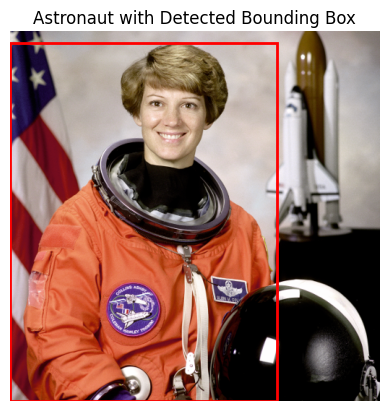

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from skimage import data

# 再次加载 astronaut 宇航员图片
astronaut_image = data.astronaut()

res = model(astronaut_image)

# 获取边界框坐标
# res[0].boxes.xyxy 中的坐标格式为 [x1, y1, x2, y2]
bbox = res[0].boxes.xyxy[0].cpu().numpy()  # 需要将数据从 GPU 移到 CPU
x1, y1, x2, y2 = bbox

# 根据边界框坐标计算矩形框的宽度和高度
width = x2 - x1
height = y2 - y1

# 创建图像和坐标轴
fig, ax = plt.subplots(1)

# 显示图片
ax.imshow(astronaut_image)

# 创建一个矩形框对象
rect = patches.Rectangle(
    (x1, y1),
    width,
    height,
    linewidth=2,
    edgecolor='r',
    facecolor='none'
)

# 把矩形框添加到坐标轴上
ax.add_patch(rect)

plt.title('Astronaut with Detected Bounding Box')
plt.axis('off')  # 隐藏坐标轴刻度和标签
plt.show()